# Cleaning dataset

Let's first load, inspect and clean the data

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)

DATA_DIR = "sample_data"  

In [2]:
## check if we got all the files, should have 2 per year - now its just one
files = sorted(glob.glob(os.path.join(DATA_DIR, "jena*.csv*")))
print(len(files), "files found:")
for f in files:
    print(" ", os.path.basename(f))

1 files found:
  jena_climate_2009_2016.csv


In [3]:
# look at one of the files to see its shape and columns
sample = pd.read_csv(files[0])
print(sample.shape)
print(sample.columns.tolist())
sample.head()

(420551, 15)
['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [4]:
# fuse the code tghter

# parse thru all the files and append - this was needed when we had 16 separate files
dfs = []
for f in files:
    part = pd.read_csv(f)
    part["source_file"] = os.path.basename(f)   # to debugging
    dfs.append(part)

# fuse all data tgether - not needed anymore
df = pd.concat(dfs, ignore_index=True)

# get date time column into datatime format. clean up errors
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S", errors="coerce")

# sort chronologically
df = df.sort_values("Date Time").reset_index(drop=True)

# Remove duplicates, can occur at start and end of file
n_before = len(df)
df = df.drop_duplicates(subset="Date Time", keep="first").reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate timestamps")

print("Shape:", df.shape)
print("Date range:", df["Date Time"].min(), "->", df["Date Time"].max())
print("Unparsed dates:", df["Date Time"].isna().sum())

Dropped 327 duplicate timestamps
Shape: (420224, 16)
Date range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00
Unparsed dates: 0


According to the TA: "To get the hourly version described in the assignment, keep every sixth row, starting from the 01:00 reading on 1 January 2009. "

In [5]:
# check if 1:00 from 1 jan 2009
print(df["Date Time"].head(7))

# get every 6th row
df = df.iloc[5::6].reset_index(drop=True)

# # round to closest min
df["Date Time"] = df["Date Time"].dt.round("min")

print("Hourly shape:", df.shape)               
print("First row:", df["Date Time"].iloc[0])   

0   2009-01-01 00:10:00
1   2009-01-01 00:20:00
2   2009-01-01 00:30:00
3   2009-01-01 00:40:00
4   2009-01-01 00:50:00
5   2009-01-01 01:00:00
6   2009-01-01 01:10:00
Name: Date Time, dtype: datetime64[ns]
Hourly shape: (70037, 16)
First row: 2009-01-01 01:00:00


ltsm requires that its data items are linear in time. That means if there are some gaps in irregular time stamps, it could cause issues. The model odesnt necessarily know that more time has passed between the two points.

One way to solve it is to interpolate a value, but the assignment removes points if there's data leakage or such things.

We can thus drop some sliding windows over these areas. Since there are not that many gaps we are not losing much traning data.

In [6]:
dt = df["Date Time"].diff().dropna()
print("Time step counts:")
print(dt.value_counts().head())

# Locate any gaps (anything other than 1 hour)
gaps = df.loc[dt[dt != pd.Timedelta(hours=1)].index, ["Date Time", "source_file"]]
gaps["gap_size"] = dt[dt != pd.Timedelta(hours=1)]
print("\nGaps found:", len(gaps))
print(gaps.head(20))

Time step counts:
Date Time
0 days 01:00:00    70031
0 days 01:10:00        2
0 days 01:20:00        1
0 days 16:50:00        1
3 days 03:10:00        1
Name: count, dtype: int64

Gaps found: 5
                Date Time                 source_file        gap_size
6729  2009-10-08 10:20:00  jena_climate_2009_2016.csv 0 days 01:20:00
38312 2013-05-16 09:30:00  jena_climate_2009_2016.csv 0 days 01:10:00
48871 2014-07-30 08:40:00  jena_climate_2009_2016.csv 0 days 01:10:00
50224 2014-09-25 09:30:00  jena_climate_2009_2016.csv 0 days 16:50:00
68490 2016-10-28 13:40:00  jena_climate_2009_2016.csv 3 days 03:10:00


for each gap that we drop, we add a segment ID (a segment consists of a bunch of non interrupted data)

In [7]:
# new segment id every time the time step isnt 1 hours
df["segment"] = (df["Date Time"].diff() != pd.Timedelta(hours=1)).cumsum()
print("Number of continuous segments:", df["segment"].nunique())
print(df.groupby("segment").size().describe())

Number of continuous segments: 6
count        6.000000
mean     11672.833333
std      11615.491008
min       1353.000000
25%       2842.500000
50%       8644.000000
75%      16339.250000
max      31583.000000
dtype: float64


In [8]:
def make_windows(data, feature_cols, target_cols, k):
    """
    data: DataFrame with a 'segment' column, sorted by time.
    Returns X of shape (N, k, n_features) and y of shape (N, n_targets).
    No window crosses a gap, because each is built inside one segment.
    """
    X_list, y_list = [], []
    for _, seg in data.groupby("segment"):
        if len(seg) <= k:          # segment too short to form even one window
            continue
        feats = seg[feature_cols].to_numpy(dtype=np.float32)
        targs = seg[target_cols].to_numpy(dtype=np.float32)
        for i in range(k, len(seg)):
            X_list.append(feats[i - k:i])   # rows t-k ... t-1
            y_list.append(targs[i])          # row t
    return np.stack(X_list), np.stack(y_list)

check missing values and any wrong data

In [9]:
print("Missing values per column:")
print(df.isna().sum())

pd.set_option("display.width", 200)
df.describe().T

Missing values per column:
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
source_file        0
segment            0
dtype: int64


,count,mean,min,25%,50%,75%,max,std
Date Time,70037,2012-12-30 09:32:40.320973312,2009-01-01 01:00:00,2010-12-31 14:20:00,2012-12-30 03:20:00,2014-12-30 08:30:00,2016-12-31 23:40:00,NaN
p (mbar),70037.0,989.213986,913.6,984.21,989.58,994.72,1015.35,8.361265
T (degC),70037.0,9.443924,-22.76,3.35,9.4,15.47,37.1,8.422167
Tpot (K),70037.0,283.486415,250.85,277.43,283.45,289.52,311.04,8.503137
Tdew (degC),70037.0,4.95448,-24.8,0.23,5.21,10.08,23.06,6.73049
rh (%),70037.0,76.02761,13.88,65.23,79.3,89.4,100.0,16.461357
VPmax (mbar),70037.0,13.570414,0.97,7.77,11.81,17.6,63.15,7.736667
VPact (mbar),70037.0,9.532792,0.81,6.21,8.86,12.36,28.25,4.183617
VPdef (mbar),70037.0,4.037556,0.0,0.87,2.19,5.29,45.41,4.893291
sh (g/kg),70037.0,6.021796,0.51,3.92,5.59,7.8,18.07,2.655797


In [10]:
# Known issue in this dataset: wind velocity columns contain -9999 placeholders
wind_cols = [c for c in df.columns if "wv" in c.lower()]
for c in wind_cols:
    print(f"{c}: min={df[c].min():.2f}, count(<0)={(df[c] < 0).sum()}")

# Check the 4 required columns for physically implausible values
target_cols = ["p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]
for c in target_cols:
    print(f"{c}: min={df[c].min():.2f}, max={df[c].max():.2f}")

wv (m/s): min=-9999.00, count(<0)=3
max. wv (m/s): min=-9999.00, count(<0)=3
p (mbar): min=913.60, max=1015.35
T (degC): min=-22.76, max=37.10
rh (%): min=13.88, max=100.00
wv (m/s): min=-9999.00, max=14.01


In [11]:

# replace anything that's -9999 with Nan
for c in target_cols:
    if c == "rh (%)":
        df.loc[df[c] <= 0, c] = np.nan # we cant have humuditiy of 0 or less
    else:
        df.loc[df[c] < -9000, c] = np.nan
# fill using past value. we are not interpolating
df[target_cols] = df[target_cols].ffill()
#print out the max and min of each feature
print(df[target_cols].describe().T[["min", "max"]])



             min      max
p (mbar)  913.60  1015.35
T (degC)  -22.76    37.10
rh (%)     13.88   100.00
wv (m/s)    0.00    14.01


min max values look normal!
lets now plot it out to double check

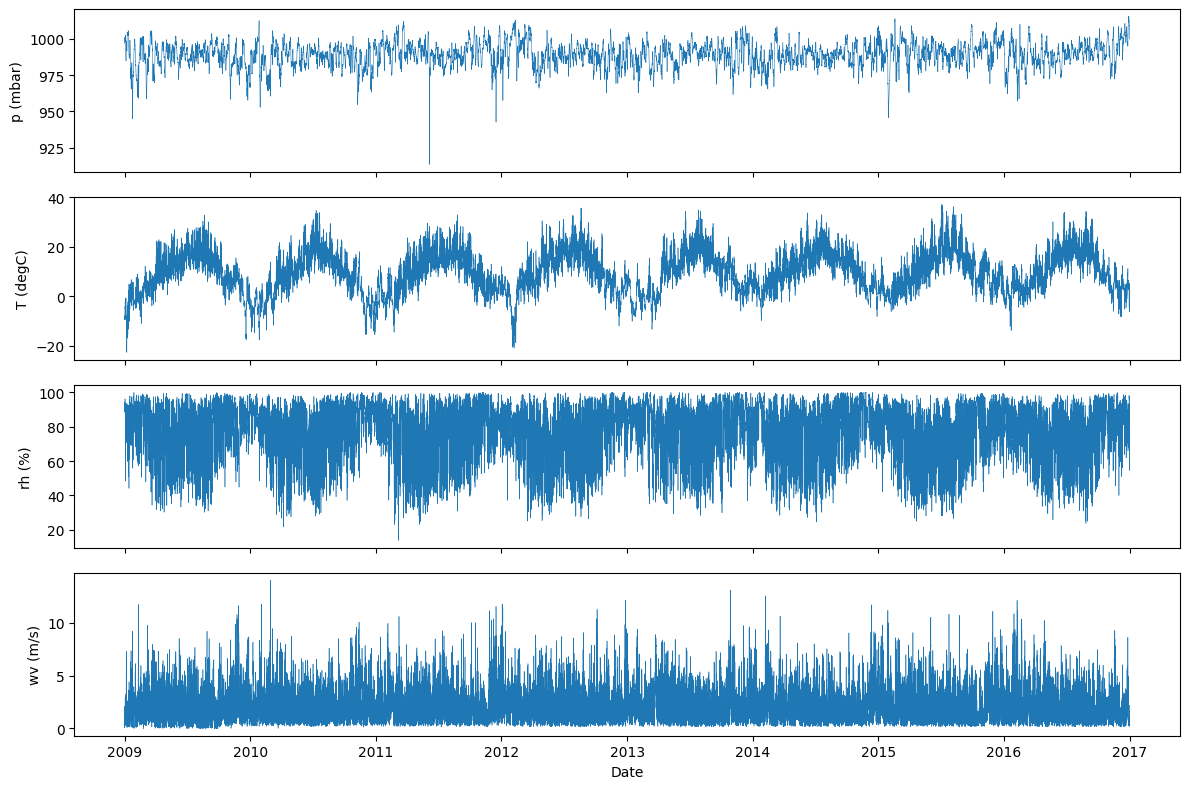

In [12]:
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(df["Date Time"], df[c], linewidth=0.4)
    ax.set_ylabel(c)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

the plots look like there are sitll some extremeties. Look at the atmospheric pressure, it has a shap spike to a low pressure. We can then plot in a closer look up to see if it was a sensor glitch or the data is legit. Also the other data seem to within good ranges, so no need to investigate.

In [13]:
checks = {
    "T (degC)": df["T (degC)"] < -30, #values found online/common sense indicating lowest mean temperature for that region in germany
    "p (mbar)": df["p (mbar)"] < 950,
    "rh (%)":   df["rh (%)"] < 5,
    "wv (m/s)": df["wv (m/s)"] > 20,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()} rows flagged")
    print(df.loc[mask, ["Date Time", "p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]].head(20))
    print()

T (degC): 0 rows flagged
Empty DataFrame
Columns: [Date Time, p (mbar), T (degC), rh (%), wv (m/s)]
Index: []

p (mbar): 31 rows flagged
                Date Time  p (mbar)  T (degC)  rh (%)  wv (m/s)
541   2009-01-23 14:00:00    947.77      0.52    90.3      8.90
542   2009-01-23 15:00:00    946.05      1.55    86.2      9.19
543   2009-01-23 16:00:00    945.13      2.00    86.5      7.77
544   2009-01-23 17:00:00    944.88      3.64    84.8      6.22
545   2009-01-23 18:00:00    944.99      4.79    81.2      6.46
546   2009-01-23 19:00:00    945.96      5.40    78.4      5.58
547   2009-01-23 20:00:00    946.90      5.10    80.3      4.47
548   2009-01-23 21:00:00    948.43      5.68    78.9      3.74
549   2009-01-23 22:00:00    949.80      5.34    77.7      4.33
21276 2011-06-06 13:20:00    913.60     25.11    53.7      3.59
25906 2011-12-16 11:20:00    949.88      3.24    85.1      8.78
25907 2011-12-16 12:20:00    947.13      3.64    83.9      5.67
25908 2011-12-16 13:20:00    94

lets observe closer to there timestamps

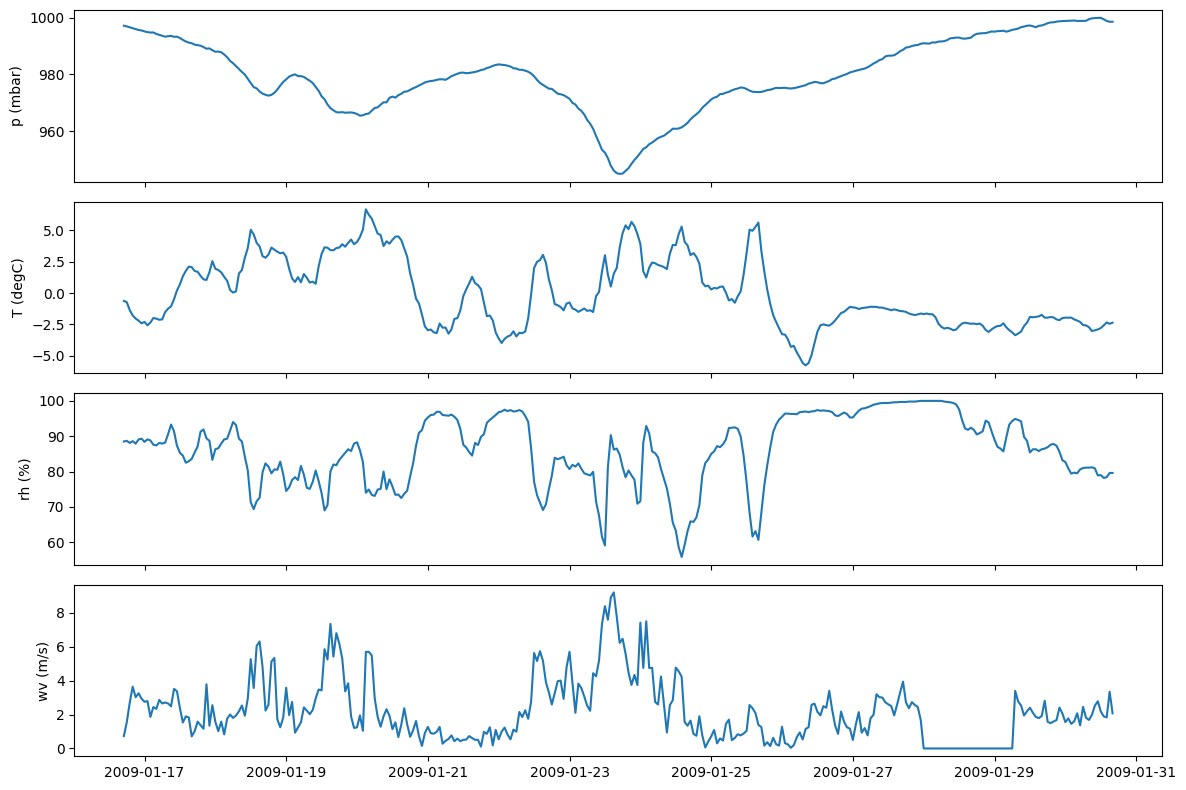

In [14]:
# zoom into to see if temperature was wrong to see the weekly pattern
week = df.iloc[544-24*7:544+24 * 7] # across two weeks
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth data, looks good

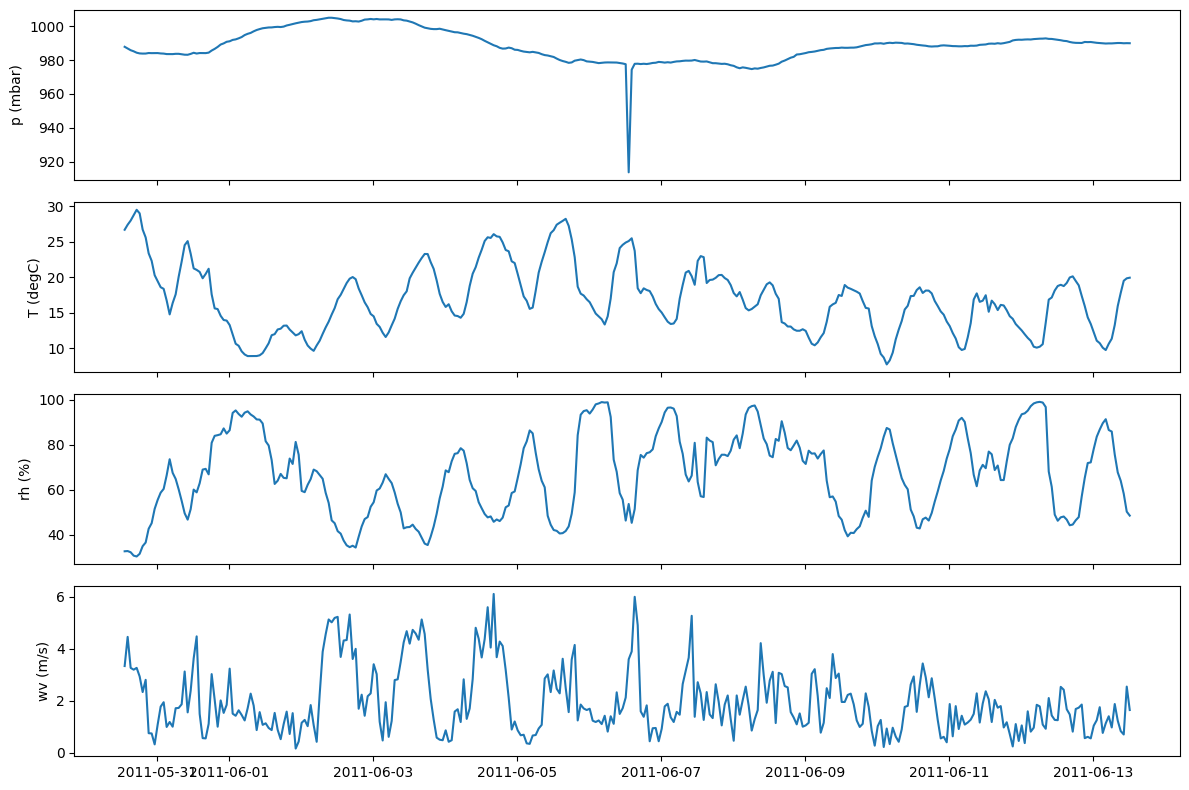

In [15]:
week = df.iloc[21276 -24*7:21276 +24 * 7] # before and after a week
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Seems like a sensor error, lets reject this point

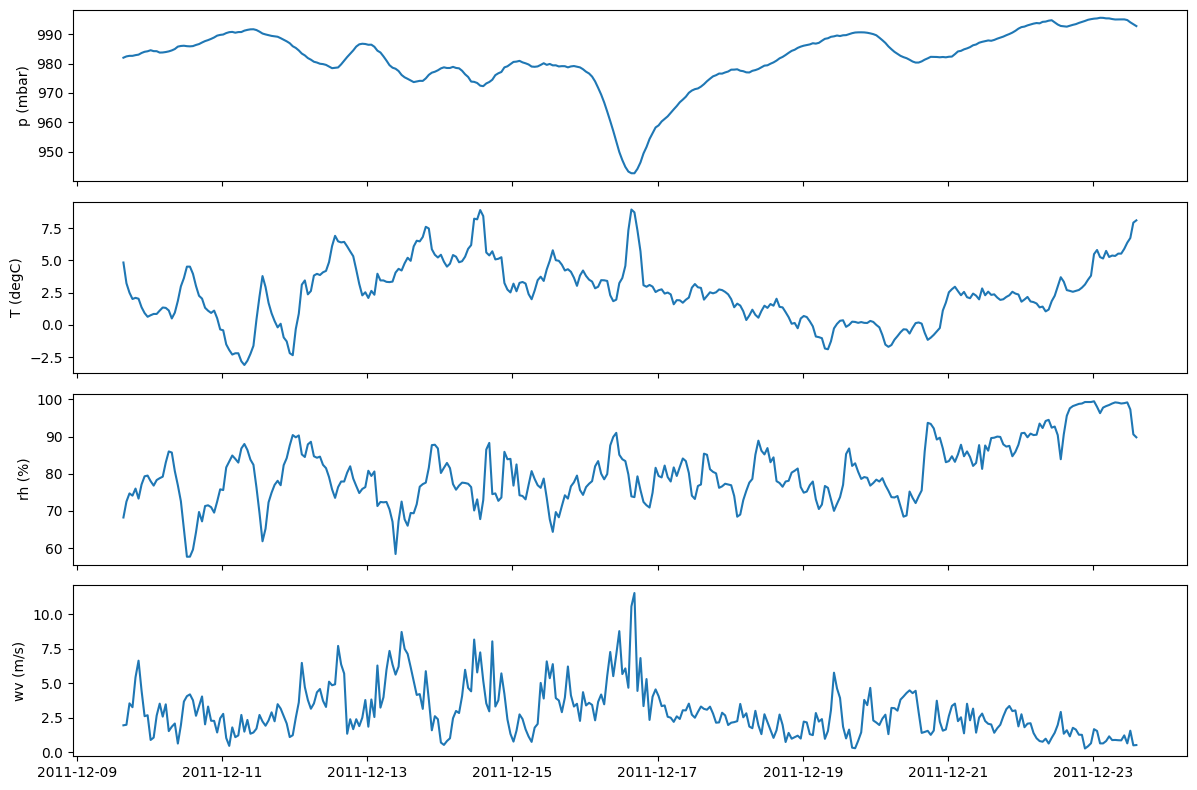

In [16]:
week = df.iloc[25910 - 24*7:25910 +24 * 7]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

looks smooth enough. we keep this data

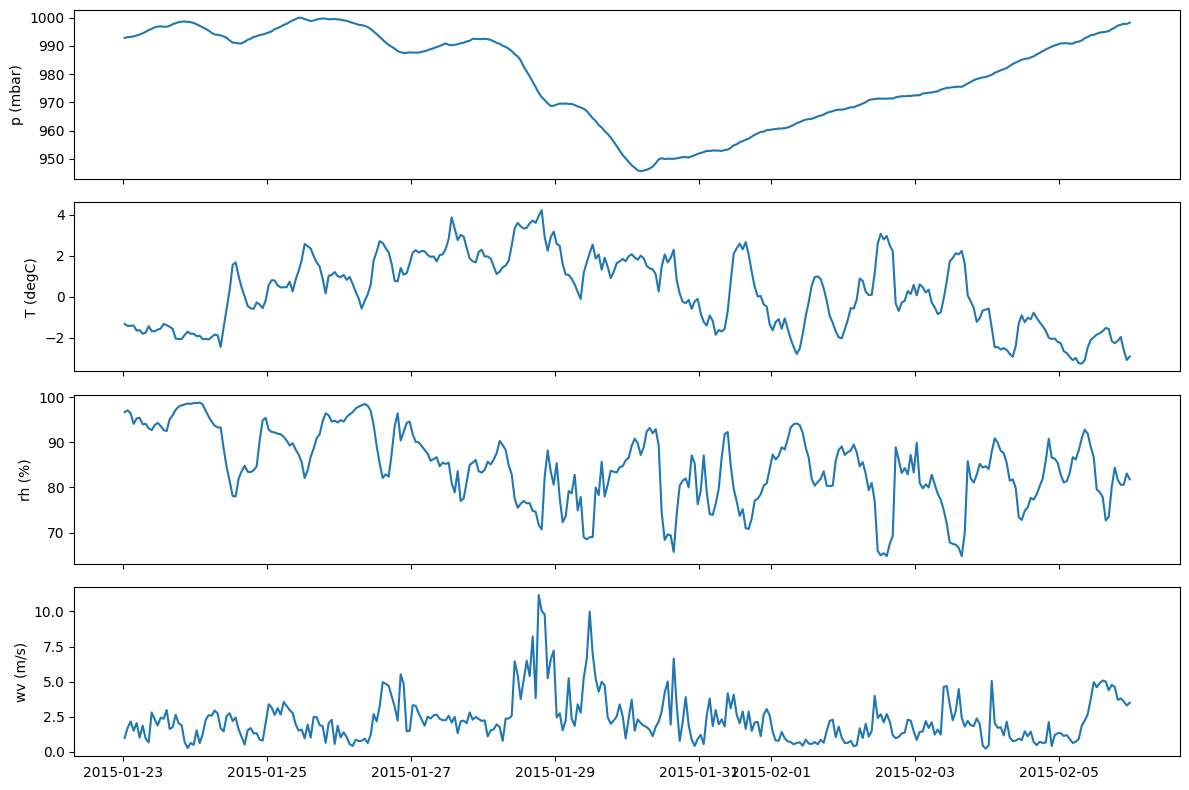

In [17]:
week = df.iloc[53263 - 7*24:53263 +7*24]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth change. That is normal.

In the end we only discard one sensor data error at timestamp 21276

In [18]:
print(df.loc[21276, target_cols]) # making sure we have the right timestamp to remove

p (mbar)    913.6
T (degC)    25.11
rh (%)       53.7
wv (m/s)     3.59
Name: 21276, dtype: object


In [19]:
df.loc[21276, target_cols] = np.nan 
# fill using past value. we are not interpolating
df[target_cols] = df[target_cols].ffill()
#print out the max and min of each feature
print(df[target_cols].describe().T[["min", "max"]])

             min      max
p (mbar)  942.65  1015.35
T (degC)  -22.76    37.10
rh (%)     13.88   100.00
wv (m/s)    0.00    14.01


MIn/Max values look normal! Let's now plot it out

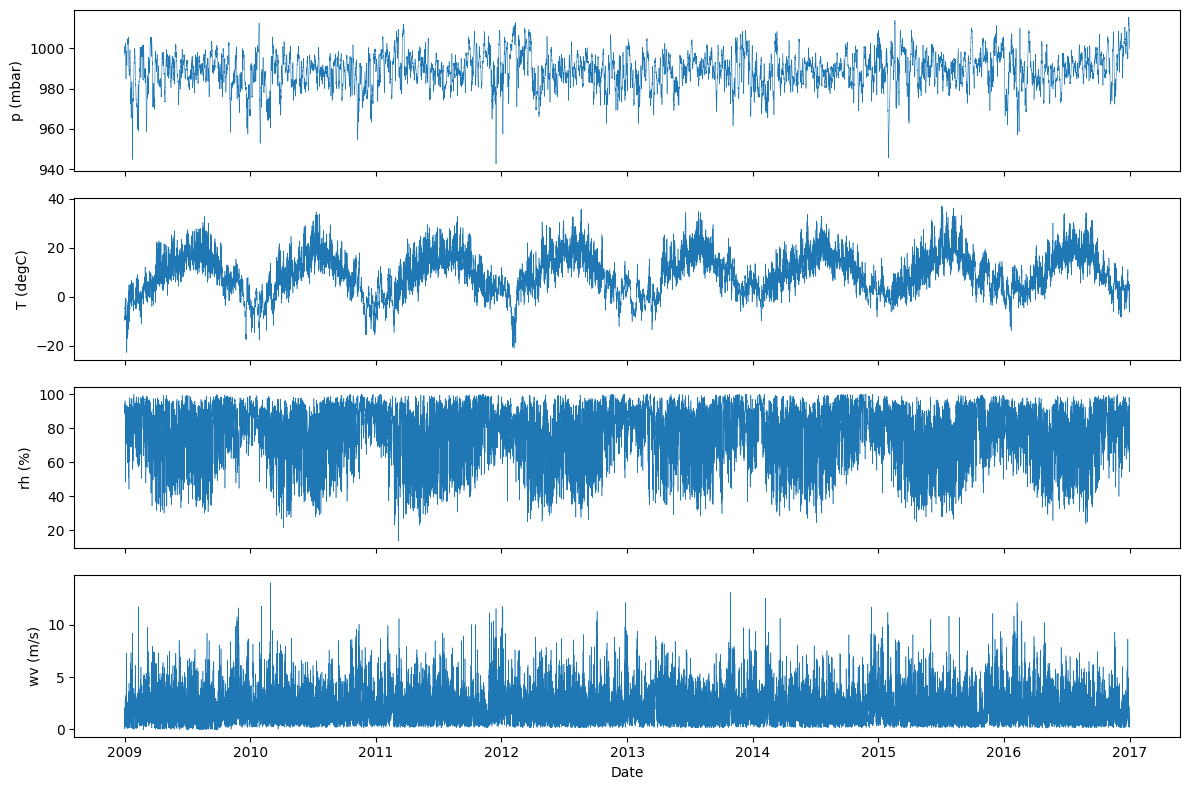

In [20]:
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(df["Date Time"], df[c], linewidth=0.4)
    ax.set_ylabel(c)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

It looks good! There is no obvious spike or erronous data.

# Splitting the dataset


Let's now split the dataset into the training, validation and test set. Note that with LTSM models, we need to keep them in chronological order.

In [21]:
df["year"] = df["Date Time"].dt.year

train_df = df[df["year"] <= 2014].copy()
val_df   = df[df["year"] == 2015].copy()
test_df  = df[df["year"] == 2016].copy()

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name}: {len(part):6d} rows")

train:  52567 rows
val:   8760 rows
test:   8710 rows


This is roughly 75.06%, 12.51%, 12.44% split. We can average it to 75, 12.5, 12.5 split. Note: the gap of 50 less rows in test is normal, since in 2016, there was a huge gap of around 2-3 days where no data was collected.

In [30]:
k = 4
batch_size = 64

# For now, four input features are also our four targets
feature_cols = target_cols.copy()

# fit scaler only on training data to avoid data leakage
scaler = StandardScaler()
scaler.fit(train_df[feature_cols])

def normalize_df(data):
    normalized = data.copy()
    normalized[feature_cols] = scaler.transform(data[feature_cols])
    return normalized

# identical normalization to all splits
train_norm = normalize_df(train_df)
val_norm = normalize_df(val_df)
test_norm = normalize_df(test_df)

X_train, y_train = make_windows(train_norm, feature_cols, target_cols, k)
X_val, y_val = make_windows(val_norm, feature_cols, target_cols, k)
X_test, y_test = make_windows(test_norm, feature_cols, target_cols, k)

# create dataloaders
def create_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = create_loader(X_train, y_train, shuffle=True)
val_loader = create_loader(X_val, y_val)
test_loader = create_loader(X_test, y_test)

# train + val combined, for the final training after early stopping
X_trainval = np.concatenate([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])
trainval_loader = create_loader(X_trainval, y_trainval, shuffle=True)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Train+Validation:", X_trainval.shape, y_trainval.shape)
print("Test:", X_test.shape, y_test.shape)
print("Train means:", train_norm[feature_cols].mean().round(4).to_dict())

Train: (52547, 4, 4) (52547, 4)
Validation: (8756, 4, 4) (8756, 4)
Train+Validation: (61303, 4, 4) (61303, 4)
Test: (8702, 4, 4) (8702, 4)
Train means: {'p (mbar)': -0.0, 'T (degC)': -0.0, 'rh (%)': 0.0, 'wv (m/s)': -0.0}


# Model Classes

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F

The following is the basis for a fully connected neural network, using ReLu as its activation function (since this is the typical default and we have no reason to believe we need something else). It is based on the code shown in tutorial 2, with expansion to allow for multiple hidden layers.

In [24]:
class FullyConnectedNN(nn.Module):
    def __init__(self, k=4, in_attrs=4, out=4, layers=2, hidden_size=8):
        """
        params:
            k: number of timesteps leading up to time t 
            in_attrs: number of attributes to be considered for each proceeding timestep
            out: number of predicted attributes
            layers: number layers, excluding output
            hidden_size: size of hidden layers
        """
        super(FullyConnectedNN, self).__init__()
        self.input_layer = nn.Linear(k * in_attrs, hidden_size)
        if layers > 1:
            # extra hidden layers (ModuleList so PyTorch trains their weights)
            self.hidden_layers = nn.ModuleList(
                [nn.Linear(hidden_size, hidden_size) for _ in range(layers - 1)]
            )
        else:
            self.hidden_layers = None
        self.output_layer = nn.Linear(hidden_size, out)

    def forward(self, x):
        x = x.flatten(1) # need to transform input dimension (batch, k, 4) -> (batch, k*4)
        hidden_result = torch.relu(self.input_layer(x))
        if self.hidden_layers is not None:
            for layer in self.hidden_layers:
                hidden_result = torch.relu(layer(hidden_result))
        return self.output_layer(hidden_result)

In [25]:
# test for FCNN
m = FullyConnectedNN()
print(m(torch.randn(2, 4, 4)).shape)              # torch.Size([2, 4])
print(FullyConnectedNN(layers=1)(torch.randn(2, 4, 4)).shape)   # also torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])


The following is a very simple LSTM, based on tutorial 9.

In [26]:
class LSTM(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=8, layers=2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=in_attrs,
            hidden_size=hidden_size,
            num_layers=layers,
            batch_first=True        # batch_first=True tells LSTM that first dimension is batch size and 2nd dim is time
        )

        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        # x: (batch_size, k, in_attrs)
        sequence_output, (h_n, c_n) = self.lstm(x)

        # Last hidden state from final LSTM layer
        last_hidden = h_n[-1]

        # predict 4 weather attributes
        return self.output(last_hidden)

**LSTM**

`batch_first=True` tells PyTorch that the first dimension is the batch size and the second dimension is time. Without it, the LSTM would interpret the dimensions incorrectly.

The LSTM receives input shaped `(batch_size, 4, 4)`.

For each observation, it updates its hidden state and cell state. After processing all four historical timesteps, it produces a representation containing information about the sequence. The last hidden state has shape `(batch_size, 8)`, and a linear layer maps the eight hidden features to the four weather predictions.

The final output shape is `(batch_size, 4)`.

In [27]:
# test LSTM
m = LSTM()
print(m(torch.randn(2, 4, 4)).shape)                 # torch.Size([2, 4])
print(LSTM(layers=1)(torch.randn(2, 4, 4)).shape)    # torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])


**RNN**

For the model of our choice, we decided to make a basic RNN to act as the middleman of complexity between a simple feedforward network and an LSTM. It uses tanh activation, the default for Pytorch's RNNs. We think it could still be effective since we have a relatively small input (with only 4-8 timesteps considered) and thus may be able to avoid vanishing gradients. 

In [36]:
class RNN(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=8, layers=2):
        """
        params:
            in_attrs: number of attributes to be considered for each proceeding timestep
            out: number of predicted attributes
            hidden_size: size of hidden representations
            layers: number layers, excluding output
        """
        super().__init__()
        # need to set batch_first = True for RNN to match data shape
        self.rnn = nn.RNN(input_size=in_attrs, hidden_size=hidden_size, num_layers=layers, nonlinearity='tanh', batch_first=True)
        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        # unpack tuple 
        sequence,_ = self.rnn(x)

        # take output at the last time step (t−1) to predict t
        return self.output(sequence[:, -1, :])

In [37]:
# quick test for RNN model
m = RNN()
print(m(torch.randn(2, 4, 4)).shape)    # torch.Size([2, 4])
print(RNN(layers=1)(torch.randn(2, 4, 4)).shape)   # also torch.Size([2, 4])
print(m(torch.randn(2, 8, 4)).shape)    # k=8 also works: torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])
torch.Size([2, 4])


# Running k=4 Models...
For all three models, we will be using the same number of layers of the primary architecture--in this case two, to be fair to the poor feedforward network and its poor capacity. The hidden representation size will always be 8--half the total input "pieces" (since we have 4 pieces of information for 4 timesteps). All of them will use Adam as their optimizer with the default learning rate of 1e-3.

We will also be using Early Stopping to preserve computational resources and find an optimal number of epochs to train for, implemented with the method below. It uses basic MSE for all models for consistency's sake and no batching. 

In [31]:
max_epochs = 50
patience = 3

def early_stopping_train(model, optimizer, train_loader, val_loader):
    no_improvement_count = 0
    best_epoch = 0
    best_loss = float("inf")
    train_losses = []  # array to save train loss for each epoch
    val_losses = []  # array to val loss for each epoch

    for epoch in range(max_epochs):
        model.train()
        train_running_loss = 0 
        for x, y in train_loader:
            optimizer.zero_grad()
            y_hat = model(x)
            loss = F.mse_loss(y_hat, y)
            loss.backward()
            optimizer.step()
            train_running_loss += loss.item()  # add up batch losses
        train_running_loss /= len(train_loader)  # compute average loss per batch for plotting

        model.eval()
        with torch.no_grad():
            running_loss = 0
            for x, y in val_loader:
                y_hat = model(x)
                running_loss += F.mse_loss(y_hat, y).item()   # .item() gives a plain number
            running_loss /= len(val_loader)  # number of batches -> average loss per batch

        # save for plotting
        train_losses.append(train_running_loss) 
        val_losses.append(running_loss)
        print(f"Epoch {epoch + 1}: train loss {train_running_loss:.4f}, val loss {running_loss:.4f}")

        if running_loss < best_loss:
            best_loss = running_loss
            best_epoch = epoch
            no_improvement_count = 0 # reset counter when loss improves
        else:
            no_improvement_count += 1
            if no_improvement_count > patience:
                print(f"Stopped early. Best epoch {best_epoch + 1}, with validation loss {best_loss:.4f}")
                return best_epoch + 1, train_losses, val_losses
    print(f"Continued to maximum epoch {max_epochs} with best validation loss {best_loss:.4f}")
    return best_epoch + 1, train_losses, val_losses 

def train_for_epochs(model, optimizer, train_loader, epochs):
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            y_hat = model(x)
            loss = F.mse_loss(y_hat, y)
            loss.backward()
            optimizer.step()
    print(f"Final training loss (last batch): {loss.item():.4f}")
    return model

# plotting function
def plot_losses(train_losses, val_losses, title):
    epochs_range = range(1, len(train_losses) + 1)
    plt.plot(epochs_range, train_losses, label="train")
    plt.plot(epochs_range, val_losses, label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss (normalized)")
    plt.title(title)
    plt.legend()
    plt.show()

Epoch 1: train loss 0.4301, val loss 0.1694
Epoch 2: train loss 0.1282, val loss 0.1269
Epoch 3: train loss 0.1120, val loss 0.1166
Epoch 4: train loss 0.1062, val loss 0.1141
Epoch 5: train loss 0.1040, val loss 0.1118
Epoch 6: train loss 0.1029, val loss 0.1116
Epoch 7: train loss 0.1022, val loss 0.1111
Epoch 8: train loss 0.1017, val loss 0.1101
Epoch 9: train loss 0.1013, val loss 0.1108
Epoch 10: train loss 0.1012, val loss 0.1097
Epoch 11: train loss 0.1008, val loss 0.1096
Epoch 12: train loss 0.1009, val loss 0.1100
Epoch 13: train loss 0.1011, val loss 0.1099
Epoch 14: train loss 0.1006, val loss 0.1095
Epoch 15: train loss 0.1003, val loss 0.1104
Epoch 16: train loss 0.1003, val loss 0.1093
Epoch 17: train loss 0.1003, val loss 0.1099
Epoch 18: train loss 0.1003, val loss 0.1093
Epoch 19: train loss 0.1003, val loss 0.1090
Epoch 20: train loss 0.1003, val loss 0.1088
Epoch 21: train loss 0.1002, val loss 0.1092
Epoch 22: train loss 0.0999, val loss 0.1094
Epoch 23: train los

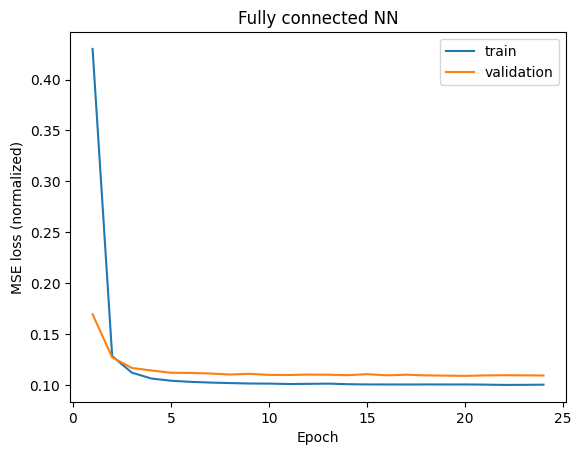

Fully connected NN - full training
Final training loss (last batch): 0.1114
Done.


In [ ]:
# Feedforward
model_fullyConnectedNN = FullyConnectedNN()
optimizer = torch.optim.Adam(model_fullyConnectedNN.parameters(), lr=1e-3) #test with Adam, I tried with SGD but it was too slow to converge
epochs, fc_train_losses, fc_val_losses = early_stopping_train(model_fullyConnectedNN, optimizer, train_loader, val_loader)

# plotting training/validation loss
plot_losses(fc_train_losses, fc_val_losses, "Fully connected NN")

# start fresh for full training
print("Fully connected NN - full training")
model_fullyConnectedNN = FullyConnectedNN()
optimizer = torch.optim.Adam(model_fullyConnectedNN.parameters(), lr=1e-3)
fc_model = train_for_epochs(model_fullyConnectedNN, optimizer, trainval_loader, epochs)
print("Done.")

Epoch 1: train loss 0.4368, val loss 0.2052
Epoch 2: train loss 0.1434, val loss 0.1283
Epoch 3: train loss 0.1148, val loss 0.1197
Epoch 4: train loss 0.1092, val loss 0.1172
Epoch 5: train loss 0.1064, val loss 0.1163
Epoch 6: train loss 0.1047, val loss 0.1147
Epoch 7: train loss 0.1032, val loss 0.1117
Epoch 8: train loss 0.1026, val loss 0.1109
Epoch 9: train loss 0.1018, val loss 0.1104
Epoch 10: train loss 0.1014, val loss 0.1104
Epoch 11: train loss 0.1011, val loss 0.1097
Epoch 12: train loss 0.1008, val loss 0.1098
Epoch 13: train loss 0.1008, val loss 0.1090
Epoch 14: train loss 0.1007, val loss 0.1145
Epoch 15: train loss 0.1003, val loss 0.1098
Epoch 16: train loss 0.1000, val loss 0.1089
Epoch 17: train loss 0.0999, val loss 0.1093
Epoch 18: train loss 0.1000, val loss 0.1092
Epoch 19: train loss 0.0999, val loss 0.1101
Epoch 20: train loss 0.0998, val loss 0.1095
Stopped early. Best epoch 16, with validation loss 0.1089


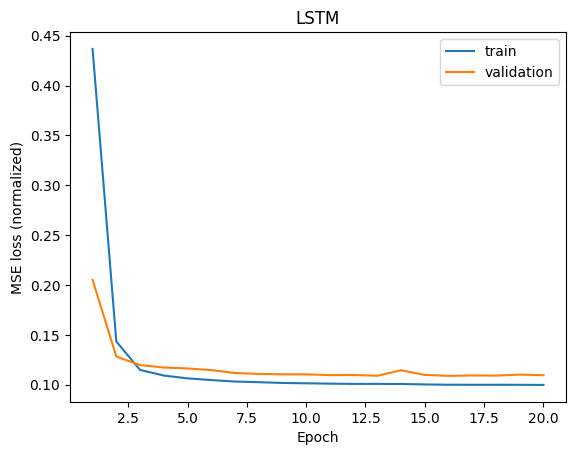

LSTM - full training
Final training loss (last batch): 0.0662
Done.


In [ ]:
# LSTM
model_LSTM = LSTM()
optimizer = torch.optim.Adam(model_LSTM.parameters(), lr=1e-3) 
epochs, lstm_train_losses, lstm_val_losses = early_stopping_train(model_LSTM, optimizer, train_loader, val_loader)

# plotting training/validation loss
plot_losses(lstm_train_losses, lstm_val_losses, "LSTM")

# start fresh for full training
print("LSTM - full training")
model_LSTM = LSTM()
optimizer = torch.optim.Adam(model_LSTM.parameters(), lr=1e-3)
lstm_model = train_for_epochs(model_LSTM, optimizer, trainval_loader, epochs)
print("Done.")

Epoch 1: train loss 0.3042, val loss 0.1484
Epoch 2: train loss 0.1224, val loss 0.1249
Epoch 3: train loss 0.1109, val loss 0.1181
Epoch 4: train loss 0.1068, val loss 0.1150
Epoch 5: train loss 0.1049, val loss 0.1132
Epoch 6: train loss 0.1039, val loss 0.1118
Epoch 7: train loss 0.1030, val loss 0.1113
Epoch 8: train loss 0.1025, val loss 0.1122
Epoch 9: train loss 0.1022, val loss 0.1108
Epoch 10: train loss 0.1021, val loss 0.1116
Epoch 11: train loss 0.1018, val loss 0.1096
Epoch 12: train loss 0.1015, val loss 0.1129
Epoch 13: train loss 0.1013, val loss 0.1110
Epoch 14: train loss 0.1014, val loss 0.1115
Epoch 15: train loss 0.1011, val loss 0.1110
Stopped early. Best epoch 11, with validation loss 0.1096


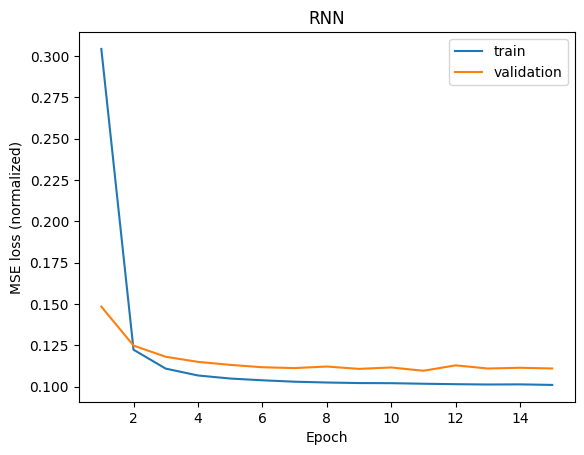

RNN - full training
Final training loss (last batch): 0.0749
Done.


In [ ]:
# RNN
model_RNN = RNN()
optimizer = torch.optim.Adam(model_RNN.parameters(), lr=1e-3) #test with Adam, I tried with SGD but it was too slow to converge
epochs, rnn_train_losses, rnn_val_losses = early_stopping_train(model_RNN, optimizer, train_loader, val_loader)

# plotting training/validation loss
plot_losses(rnn_train_losses, rnn_val_losses, "RNN")

# start fresh for full training
print("RNN - full training")
model_RNN = RNN()
optimizer = torch.optim.Adam(model_RNN.parameters(), lr=1e-3)
rnn_model = train_for_epochs(model_RNN, optimizer, trainval_loader, epochs)
print("Done.")

In [ ]:
def single_point_error_prop(model, x, y, err_func=F.mse_loss):
    """
    params:
        model: the model with a forward method to run
        x: the data from t-k to t-1
        y: the expected output from t to t+n
    """
    input_data = x
    errs = []
    model.eval()
    with torch.no_grad():
        for yt in y:
            y_hat = model(input_data)
            errs.append(err_func(y_hat, yt))
            input_data = input_data[1:] + y_hat
    return errs